# Data Mining Project
# Heart desease classifier
## Done by Jaafar Ghemrawi

### import libraries

In [6]:
import pandas as pd
import csv
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from scipy import stats

### read CSV Data

In [7]:
file_path= "heart disease dataset.csv"


In [8]:

df = pd.read_csv(file_path)
df



,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


### calculate Mode, Mean, Median, Max and Min value for some column

In [9]:
# Calculate and display individual statistics
print("Mode:", df['age'].mode()[0])
print("Median:", df['age'].median())
print("Mean:", df['age'].mean())
print("Max:", df['age'].max())
print("Min:", df['age'].min())

Mode: 58
Median: 55.0
Mean: 54.366336633663366
Max: 77
Min: 29


In [10]:
# Calculate and display individual statistics
print("Mode:", df['trestbps'].mode()[0])
print("Median:", df['trestbps'].median())
print("Mean:", df['trestbps'].mean())
print("Max:", df['trestbps'].max())
print("Min:", df['trestbps'].min())

Mode: 120
Median: 130.0
Mean: 131.62376237623764
Max: 200
Min: 94


In [11]:
# Calculate and display individual statistics
print("Mode:", df['chol'].mode()[0])
print("Median:", df['chol'].median())
print("Mean:", df['chol'].mean())
print("Max:", df['chol'].max())
print("Min:", df['chol'].min())

Mode: 197
Median: 240.0
Mean: 246.26402640264027
Max: 564
Min: 126


### calculate correlation matrix to get high correlated data with target

In [12]:
scaler = StandardScaler()
df_normalized = pd.DataFrame(scaler.fit_transform(df[1:]), columns=df.columns)
#df_normalized = df_normalized.drop('ta', axis=1, inplace=False)
df_normalized

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,-1.911874,0.682656,1.014001,-0.090146,0.071241,-0.412968,0.895654,1.630825,-0.698344,2.126829,-2.298111,-0.716216,-0.523194,0.917313
1,-1.470785,-1.464866,0.038752,-0.090146,-0.816360,-0.412968,-1.009188,0.975951,-0.698344,0.314610,0.975613,-0.716216,-0.523194,0.917313
2,0.183300,0.682656,0.038752,-0.660884,-0.198899,-0.412968,0.895654,1.237901,-0.698344,-0.203167,0.975613,-0.716216,-0.523194,0.917313
3,0.293573,-1.464866,-0.936498,-0.660884,2.077990,-0.412968,0.895654,0.583026,1.431958,-0.375760,0.975613,-0.716216,-0.523194,0.917313
4,0.293573,0.682656,-0.936498,0.480591,-1.047908,-0.412968,0.895654,-0.071848,-0.698344,-0.548352,-0.661249,-0.716216,-2.169074,0.917313
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
297,0.293573,-1.464866,-0.936498,0.480591,-0.102420,-0.412968,0.895654,-1.163306,1.431958,-0.720944,-0.661249,-0.716216,1.122687,-1.090140
298,-1.029695,0.682656,1.989251,-1.231621,0.341380,-0.412968,0.895654,-0.770381,-0.698344,0.142017,-0.661249,-0.716216,1.122687,-1.090140
299,1.506568,0.682656,-0.936498,0.708886,-1.028612,2.421495,0.895654,-0.377456,-0.698344,2.040533,-0.661249,1.241225,1.122687,-1.090140
300,0.293573,0.682656,-0.936498,-0.090146,-2.224944,-0.412968,0.895654,-1.512572,1.431958,0.142017,-0.661249,0.262505,1.122687,-1.090140


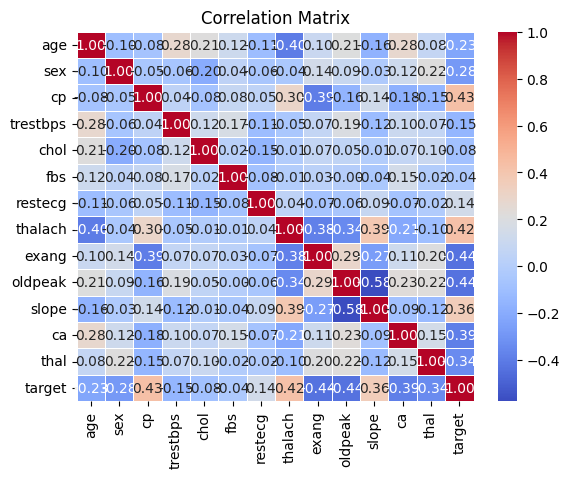

In [13]:

correlation_matrix = df_normalized.corr()

# Visualize the correlation matrix using a heatmap
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

.
.
.
.
.
### put important data in new DataFrame

In [14]:
new_dataframe = pd.DataFrame()
new_dataframe['age']=df_normalized['age']
new_dataframe['sex']=df_normalized['sex']
new_dataframe['cp']=df_normalized['cp']
new_dataframe['thalach']=df_normalized['thalach']
new_dataframe['exang']=df_normalized['exang']
new_dataframe['oldpeak']=df_normalized['oldpeak']
new_dataframe['slope']=df_normalized['slope']
new_dataframe['ca']=df_normalized['ca']
new_dataframe['thal']=df_normalized['thal']
new_dataframe['trestbps']=df_normalized['trestbps']

new_dataframe['target']=df['target']

new_dataframe

,age,sex,cp,thalach,exang,oldpeak,slope,ca,thal,trestbps,target
0,-1.911874,0.682656,1.014001,1.630825,-0.698344,2.126829,-2.298111,-0.716216,-0.523194,-0.090146,1
1,-1.470785,-1.464866,0.038752,0.975951,-0.698344,0.314610,0.975613,-0.716216,-0.523194,-0.090146,1
2,0.183300,0.682656,0.038752,1.237901,-0.698344,-0.203167,0.975613,-0.716216,-0.523194,-0.660884,1
3,0.293573,-1.464866,-0.936498,0.583026,1.431958,-0.375760,0.975613,-0.716216,-0.523194,-0.660884,1
4,0.293573,0.682656,-0.936498,-0.071848,-0.698344,-0.548352,-0.661249,-0.716216,-2.169074,0.480591,1
...,...,...,...,...,...,...,...,...,...,...,...
297,0.293573,-1.464866,-0.936498,-1.163306,1.431958,-0.720944,-0.661249,-0.716216,1.122687,0.480591,0
298,-1.029695,0.682656,1.989251,-0.770381,-0.698344,0.142017,-0.661249,-0.716216,1.122687,-1.231621,0
299,1.506568,0.682656,-0.936498,-0.377456,-0.698344,2.040533,-0.661249,1.241225,1.122687,0.708886,0
300,0.293573,0.682656,-0.936498,-1.512572,1.431958,0.142017,-0.661249,0.262505,1.122687,-0.090146,0


### Apply PCA to visualize data

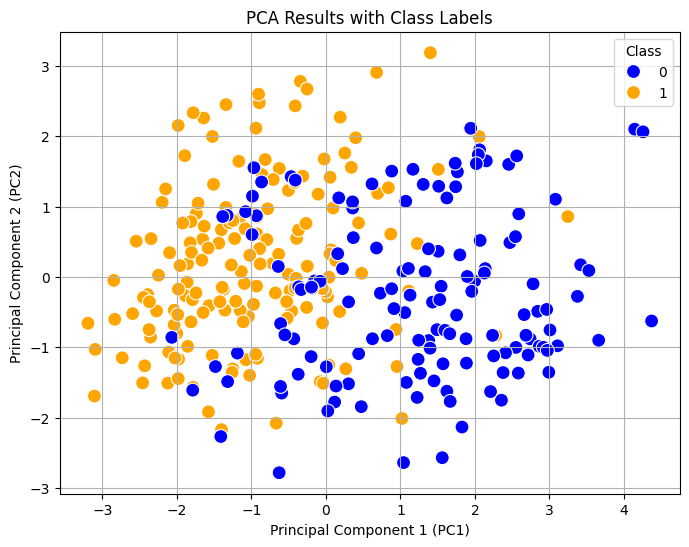

In [15]:
# Separate features and labels
X = new_dataframe.iloc[:, :-1]  # Features (first four columns)
y = new_dataframe['target'] 

# Standardize the features
scaler = StandardScaler()
X_standardized = scaler.fit_transform(X)

# Apply PCA with two components
pca = PCA(n_components=2)
pca_result = pca.fit_transform(X_standardized)

pca_df = pd.DataFrame(data={'PC1': pca_result[:, 0], 'PC2': pca_result[:, 1], 'cardio': y})

# Plot the PCA results with color-coded classes
plt.figure(figsize=(8, 6))
sns.scatterplot(x='PC1', y='PC2', hue='cardio', data=pca_df, palette={0: 'blue', 1: 'orange'}, marker='o', s=100)
plt.title('PCA Results with Class Labels')
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.legend(title='Class', loc='upper right')
plt.grid(True)
plt.show()



### Apply random forest on PCA 2D Data

Accuracy: 0.87
Sensitivity (Recall): 0.84
Specificity: 0.90


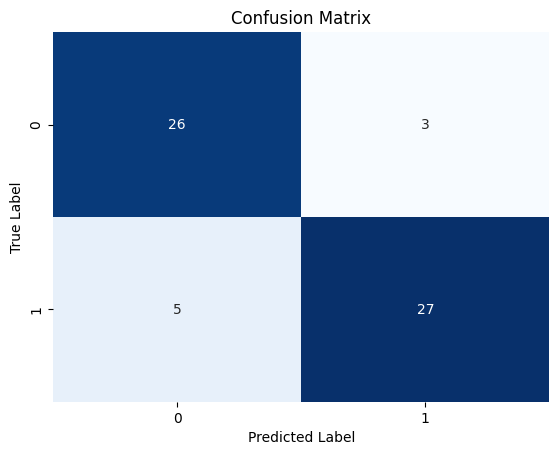

In [16]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_standardized, y, test_size=0.2, random_state=42)

# Apply Random Forest Classifier
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(X_train, y_train)

# Predict on the test set
y_pred = rf_classifier.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.2f}')

# Create a confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

TP = conf_matrix[1, 1]
TN = conf_matrix[0, 0]
FP = conf_matrix[0, 1]
FN = conf_matrix[1, 0]

# Calculate sensitivity (recall)
sensitivity = TP / (TP + FN)

# Calculate specificity
specificity = TN / (TN + FP)

# Display the results
print(f'Sensitivity (Recall): {sensitivity:.2f}')
print(f'Specificity: {specificity:.2f}')


sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

### apply naive Bayesian classifier on PCA data

Accuracy: 0.85
Sensitivity (Recall): 0.81
Specificity: 0.90


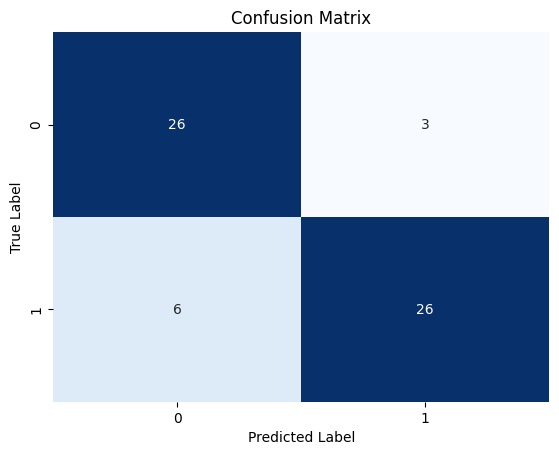

In [17]:
naive_bayes_classifier = GaussianNB()
naive_bayes_classifier.fit(X_train, y_train)

# Predict on the test set
y_pred = naive_bayes_classifier.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.2f}')

# Create a confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

TP = conf_matrix[1, 1]
TN = conf_matrix[0, 0]
FP = conf_matrix[0, 1]
FN = conf_matrix[1, 0]

# Calculate sensitivity (recall)
sensitivity = TP / (TP + FN)

# Calculate specificity
specificity = TN / (TN + FP)

# Display the results
print(f'Sensitivity (Recall): {sensitivity:.2f}')
print(f'Specificity: {specificity:.2f}')


sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

### Apply Logistic regression on PCA Data

Accuracy: 0.85
Sensitivity (Recall): 0.88
Specificity: 0.83


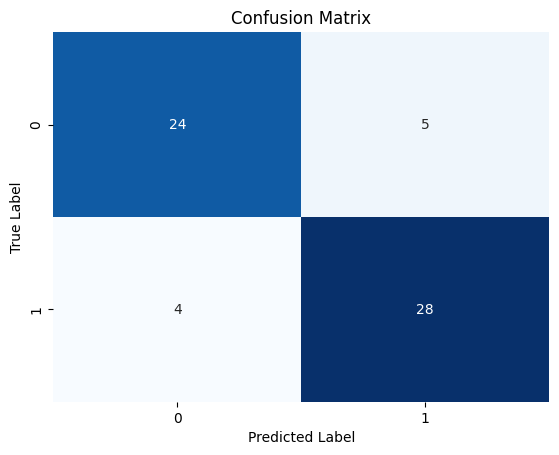

In [18]:
# Apply Logistic Regression
logistic_regression_model = LogisticRegression(max_iter=15000, random_state=42)
logistic_regression_model.fit(X_train, y_train)


# Predict on the test set
y_pred = logistic_regression_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.2f}')

# Create a confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)



TP = conf_matrix[1, 1]
TN = conf_matrix[0, 0]
FP = conf_matrix[0, 1]
FN = conf_matrix[1, 0]

# Calculate sensitivity (recall)
sensitivity = TP / (TP + FN)

# Calculate specificity
specificity = TN / (TN + FP)

# Display the results
print(f'Sensitivity (Recall): {sensitivity:.2f}')
print(f'Specificity: {specificity:.2f}')




sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

### Apply Random forest on Normalized Data

Accuracy: 0.87
Sensitivity (Recall): 0.84
Specificity: 0.90


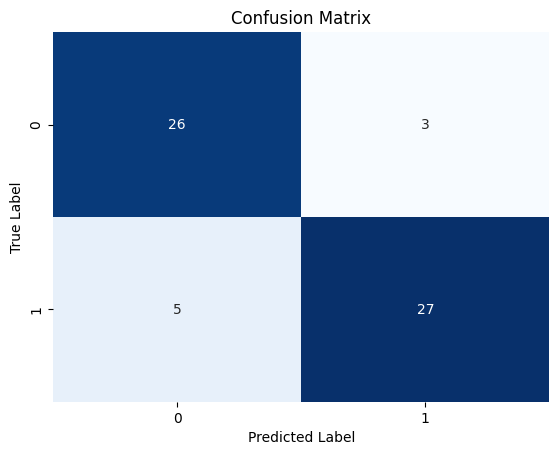

In [19]:
X = new_dataframe.iloc[:, :-1]  # Features (first four columns)
y = new_dataframe['target']       # Labels (fifth column)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Apply Random Forest Classifier
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(X_train, y_train)

# Predict on the test set
y_pred = rf_classifier.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.2f}')

# Create a confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)


TP = conf_matrix[1, 1]
TN = conf_matrix[0, 0]
FP = conf_matrix[0, 1]
FN = conf_matrix[1, 0]

# Calculate sensitivity (recall)
sensitivity = TP / (TP + FN)

# Calculate specificity
specificity = TN / (TN + FP)

# Display the results
print(f'Sensitivity (Recall): {sensitivity:.2f}')
print(f'Specificity: {specificity:.2f}')


sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


### Apply Naive Bayesian classifier on Normalized Data

Accuracy: 0.85
Sensitivity (Recall): 0.81
Specificity: 0.90


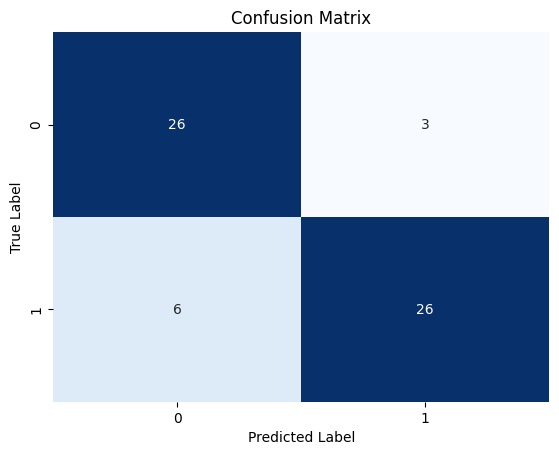

In [20]:
naive_bayes_classifier = GaussianNB()
naive_bayes_classifier.fit(X_train, y_train)

# Predict on the test set
y_pred = naive_bayes_classifier.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.2f}')

# Create a confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

TP = conf_matrix[1, 1]
TN = conf_matrix[0, 0]
FP = conf_matrix[0, 1]
FN = conf_matrix[1, 0]

# Calculate sensitivity (recall)
sensitivity = TP / (TP + FN)

# Calculate specificity
specificity = TN / (TN + FP)

# Display the results
print(f'Sensitivity (Recall): {sensitivity:.2f}')
print(f'Specificity: {specificity:.2f}')

sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

### Apply Logistic regression on Normalized Data

Accuracy: 0.85
Sensitivity (Recall): 0.88
Specificity: 0.83


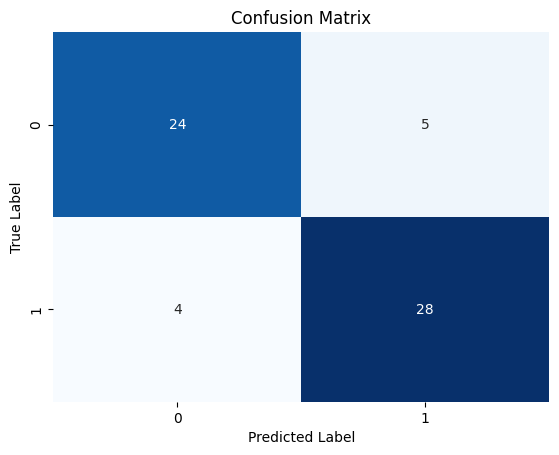

In [21]:
# Apply Logistic Regression
logistic_regression_model = LogisticRegression(max_iter=15000, random_state=42)
logistic_regression_model.fit(X_train, y_train)


# Predict on the test set
y_pred = logistic_regression_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.2f}')

# Create a confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)


TP = conf_matrix[1, 1]
TN = conf_matrix[0, 0]
FP = conf_matrix[0, 1]
FN = conf_matrix[1, 0]

# Calculate sensitivity (recall)
sensitivity = TP / (TP + FN)

# Calculate specificity
specificity = TN / (TN + FP)

# Display the results
print(f'Sensitivity (Recall): {sensitivity:.2f}')
print(f'Specificity: {specificity:.2f}')


sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

### Apply Random forest, Naive Bayesian classifier and logistic regression on Original Data

Accuracy: 0.84
Sensitivity (Recall): 0.84
Specificity: 0.83


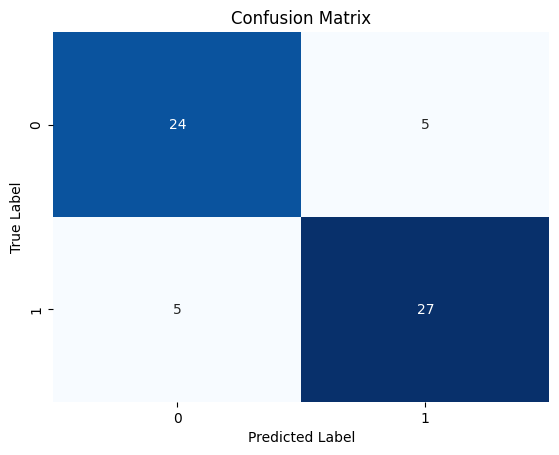

In [22]:
X = df.iloc[:, :-1]  # Features (first four columns)
y = df['target']       # Labels (fifth column)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Apply Random Forest Classifier
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(X_train, y_train)

# Predict on the test set
y_pred = rf_classifier.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.2f}')

# Create a confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)


TP = conf_matrix[1, 1]
TN = conf_matrix[0, 0]
FP = conf_matrix[0, 1]
FN = conf_matrix[1, 0]

# Calculate sensitivity (recall)
sensitivity = TP / (TP + FN)

# Calculate specificity
specificity = TN / (TN + FP)

# Display the results
print(f'Sensitivity (Recall): {sensitivity:.2f}')
print(f'Specificity: {specificity:.2f}')


sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


Accuracy: 0.87
Sensitivity (Recall): 0.84
Specificity: 0.90


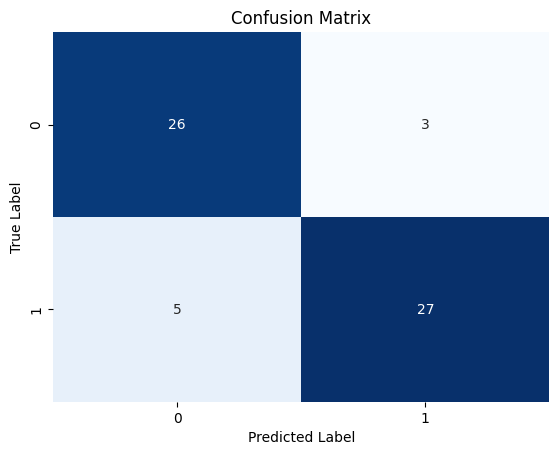

In [23]:
naive_bayes_classifier = GaussianNB()
naive_bayes_classifier.fit(X_train, y_train)

# Predict on the test set
y_pred = naive_bayes_classifier.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.2f}')

# Create a confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)



TP = conf_matrix[1, 1]
TN = conf_matrix[0, 0]
FP = conf_matrix[0, 1]
FN = conf_matrix[1, 0]

# Calculate sensitivity (recall)
sensitivity = TP / (TP + FN)

# Calculate specificity
specificity = TN / (TN + FP)

# Display the results
print(f'Sensitivity (Recall): {sensitivity:.2f}')
print(f'Specificity: {specificity:.2f}')



sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

Accuracy: 0.89
Sensitivity (Recall): 0.91
Specificity: 0.86


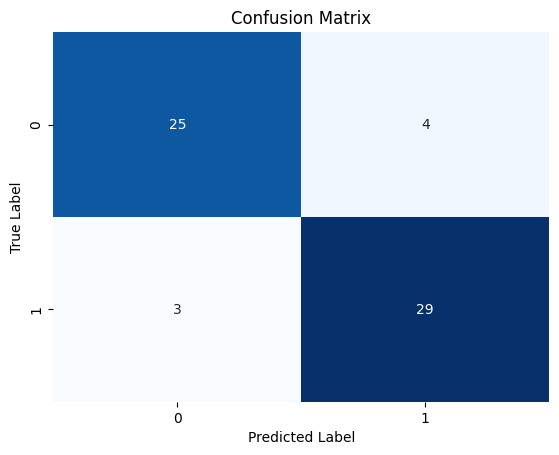

In [24]:
# Apply Logistic Regression
logistic_regression_model = LogisticRegression(max_iter=15000, random_state=42)
logistic_regression_model.fit(X_train, y_train)


# Predict on the test set
y_pred = logistic_regression_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.2f}')

# Create a confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

TP = conf_matrix[1, 1]
TN = conf_matrix[0, 0]
FP = conf_matrix[0, 1]
FN = conf_matrix[1, 0]

# Calculate sensitivity (recall)
sensitivity = TP / (TP + FN)

# Calculate specificity
specificity = TN / (TN + FP)

# Display the results
print(f'Sensitivity (Recall): {sensitivity:.2f}')
print(f'Specificity: {specificity:.2f}')



sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()